# Deep Convolutional Generative Adversarial Network Example

Build a deep convolutional generative adversarial network (DCGAN) to
generate digit images from a noise distribution with JAX, using Flax
'layers' and 'model' API.

Flax (NNX) is the neural network library of the JAX ecosystem: it provides
ready-made layers (`nnx.Linear`, `nnx.Conv`, `nnx.ConvTranspose`,
`nnx.BatchNorm`, ...) and a `nnx.Module` class to assemble them into a model.
The optimizers come from Optax, the JAX library of optimizers.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

## DCGAN Overview

<img src="https://camo.githubusercontent.com/45e147fc9dfcf6a8e5df2c9b985078258b9974e3/68747470733a2f2f63646e2d696d616765732d312e6d656469756d2e636f6d2f6d61782f313030302f312a33394e6e6e695f6e685044614c7539416e544c6f57772e706e67" alt="dcgan" style="width: 1000px;"/>

References:
- [Unsupervised representation learning with deep convolutional generative adversarial networks](https://arxiv.org/pdf/1511.06434). A Radford, L Metz, S Chintala, 2016.
- [Understanding the difficulty of training deep feedforward neural networks](http://proceedings.mlr.press/v9/glorot10a.html). X Glorot, Y Bengio. Aistats 9, 249-256
- [Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift](https://arxiv.org/abs/1502.03167). Sergey Ioffe, Christian Szegedy. 2015.

## MNIST Dataset Overview

This example is using MNIST handwritten digits. The dataset contains 60,000 examples for training and 10,000 examples for testing. The digits have been size-normalized and centered in a fixed-size image (28x28 pixels) with values from 0 to 255.

In this example, each image will be converted to float32 and normalized from [0, 255] to [0, 1].

![MNIST Dataset](http://neuralnetworksanddeeplearning.com/images/mnist_100_digits.png)

More info: http://yann.lecun.com/exdb/mnist/

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import numpy as np
import optax
from flax import nnx

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import load_mnist, batch_iterator

In [2]:
# MNIST Dataset parameters.
num_features = 784  # data features (img shape: 28*28).

# Training parameters.
lr_generator = 0.0002
lr_discriminator = 0.0002
training_steps = 2000
batch_size = 64
display_step = 200

# Network parameters.
noise_dim = 100  # Noise data points.

In [3]:
# Prepare MNIST data.
(x_train, y_train), (x_test, y_test) = load_mnist()
# Convert to float32.
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)
# Normalize images value from [0, 255] to [0, 1].
x_train, x_test = x_train / 255., x_test / 255.

In [4]:
# Shuffle and batch data (a simple data loader, see 'common/datasets.py').
train_data = batch_iterator(x_train, y_train, batch_size)

In [5]:
# Create Flax Models.
# Generator Network
# Input: Noise, Output: Image
class Generator(nnx.Module):
    # Set layers.
    # 'rngs' provides the random keys used to initialize the layers weights.
    def __init__(self, rngs):
        self.fc1 = nnx.Linear(noise_dim, 7 * 7 * 128, rngs=rngs)
        self.bn1 = nnx.BatchNorm(7 * 7 * 128, rngs=rngs)
        self.conv2tr1 = nnx.ConvTranspose(128, 64, kernel_size=(5, 5), strides=(2, 2),
                                          padding='SAME', rngs=rngs)
        self.bn2 = nnx.BatchNorm(64, rngs=rngs)
        self.conv2tr2 = nnx.ConvTranspose(64, 1, kernel_size=(5, 5), strides=(2, 2),
                                          padding='SAME', rngs=rngs)

    # Set forward pass.
    def __call__(self, x):
        x = self.fc1(x)
        x = self.bn1(x)
        x = nnx.leaky_relu(x, negative_slope=0.2)
        # Reshape to a 4-D array of images: (batch, height, width, channels)
        # New shape: (batch, 7, 7, 128)
        x = jnp.reshape(x, [-1, 7, 7, 128])
        # Deconvolution, image shape: (batch, 14, 14, 64)
        x = self.conv2tr1(x)
        x = self.bn2(x)
        x = nnx.leaky_relu(x, negative_slope=0.2)
        # Deconvolution, image shape: (batch, 28, 28, 1)
        x = self.conv2tr2(x)
        x = jnp.tanh(x)
        return x

# Discriminator Network
# Input: Image, Output: Prediction Real/Fake Image
class Discriminator(nnx.Module):
    # Set layers.
    def __init__(self, rngs):
        self.conv1 = nnx.Conv(1, 64, kernel_size=(5, 5), strides=(2, 2),
                              padding='SAME', rngs=rngs)
        self.bn1 = nnx.BatchNorm(64, rngs=rngs)
        self.conv2 = nnx.Conv(64, 128, kernel_size=(5, 5), strides=(2, 2),
                              padding='SAME', rngs=rngs)
        self.bn2 = nnx.BatchNorm(128, rngs=rngs)
        self.fc1 = nnx.Linear(7 * 7 * 128, 1024, rngs=rngs)
        self.bn3 = nnx.BatchNorm(1024, rngs=rngs)
        self.fc2 = nnx.Linear(1024, 2, rngs=rngs)

    # Set forward pass.
    def __call__(self, x):
        x = jnp.reshape(x, [-1, 28, 28, 1])
        x = self.conv1(x)
        x = self.bn1(x)
        x = nnx.leaky_relu(x, negative_slope=0.2)
        x = self.conv2(x)
        x = self.bn2(x)
        x = nnx.leaky_relu(x, negative_slope=0.2)
        # Flatten to a 1-D vector, shape: (batch, 7*7*128)
        x = jnp.reshape(x, [x.shape[0], -1])
        x = self.fc1(x)
        x = self.bn3(x)
        x = nnx.leaky_relu(x, negative_slope=0.2)
        return self.fc2(x)

# Build neural network models.
generator = Generator(rngs=nnx.Rngs(0))
discriminator = Discriminator(rngs=nnx.Rngs(1))

In [6]:
# Losses.
# The discriminator outputs 2 scores per image: class 0 = fake, class 1 = real.
def generator_loss(reconstructed_image):
    # The generator wants its images to be classified as real (1).
    gen_loss = jnp.mean(optax.softmax_cross_entropy_with_integer_labels(
        logits=reconstructed_image, labels=jnp.ones(len(reconstructed_image), dtype=jnp.int32)))
    return gen_loss

def discriminator_loss(disc_fake, disc_real):
    # The discriminator wants real images classified as real (1), fake as fake (0).
    disc_loss_real = jnp.mean(optax.softmax_cross_entropy_with_integer_labels(
        logits=disc_real, labels=jnp.ones(len(disc_real), dtype=jnp.int32)))
    disc_loss_fake = jnp.mean(optax.softmax_cross_entropy_with_integer_labels(
        logits=disc_fake, labels=jnp.zeros(len(disc_fake), dtype=jnp.int32)))
    return disc_loss_real + disc_loss_fake

# Optimizers.
# 'wrt=nnx.Param' tells each optimizer to update all its model parameters.
optimizer_gen = nnx.Optimizer(generator, optax.adam(lr_generator), wrt=nnx.Param)
optimizer_disc = nnx.Optimizer(discriminator, optax.adam(lr_discriminator), wrt=nnx.Param)

In [7]:
# Optimization process. Inputs: real image and a random key (to generate noise).
# @nnx.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@nnx.jit
def run_optimization(generator, discriminator, optimizer_gen, optimizer_disc,
                     real_images, key):
    # Rescale to [-1, 1], the input range of the discriminator
    real_images = real_images * 2. - 1.
    key_disc, key_gen = jax.random.split(key)

    # Generate noise (random values from a normal distribution, centered on 0).
    noise = jax.random.normal(key_disc, [batch_size, noise_dim])

    # Discriminator loss, as a function of the discriminator. 'nnx.grad'
    # differentiates with respect to the first argument only (the generator
    # is passed as a second argument, so it is not updated here).
    def disc_loss_fn(discriminator, generator):
        fake_images = generator(noise)
        disc_fake = discriminator(fake_images)
        disc_real = discriminator(real_images)
        return discriminator_loss(disc_fake, disc_real)

    # Update the discriminator following its gradients.
    disc_loss, gradients_disc = nnx.value_and_grad(disc_loss_fn)(discriminator, generator)
    optimizer_disc.update(discriminator, gradients_disc)

    # Generate noise.
    noise = jax.random.normal(key_gen, [batch_size, noise_dim])

    # Generator loss, as a function of the generator.
    def gen_loss_fn(generator, discriminator):
        fake_images = generator(noise)
        disc_fake = discriminator(fake_images)
        return generator_loss(disc_fake)

    # Update the generator following its gradients.
    gen_loss, gradients_gen = nnx.value_and_grad(gen_loss_fn)(generator, discriminator)
    optimizer_gen.update(generator, gradients_gen)

    return gen_loss, disc_loss

In [8]:
# Compute the initial losses, before training.
# Batch normalization behaves differently at training and inference time:
# '.eval()' sets the models to inference mode (use the running statistics).
generator.eval()
discriminator.eval()
key = jax.random.key(2)
key, noise_key = jax.random.split(key)
batch_x, _ = next(train_data)
noise = jax.random.normal(noise_key, [batch_size, noise_dim])
gen_loss = generator_loss(discriminator(generator(noise)))
disc_loss = discriminator_loss(discriminator(generator(noise)), discriminator(batch_x * 2. - 1.))
print("initial: gen_loss: %f, disc_loss: %f" % (gen_loss, disc_loss))

# '.train()' sets the models to training mode (use the batch statistics).
generator.train()
discriminator.train()

# Run training for the given number of steps.
for step in range(1, training_steps + 1):
    # Get the next batch of data (only the images are needed, not the labels).
    batch_x, _ = next(train_data)
    # Get a new random key for this step's noise.
    key, step_key = jax.random.split(key)
    # Run the optimization.
    gen_loss, disc_loss = run_optimization(generator, discriminator, optimizer_gen,
                                           optimizer_disc, batch_x, step_key)

    if step % display_step == 0:
        print("step: %i, gen_loss: %f, disc_loss: %f" % (step, gen_loss, disc_loss))

initial: gen_loss: 0.669336, disc_loss: 1.252481


step: 200, gen_loss: 1.371511, disc_loss: 0.758955


step: 400, gen_loss: 1.878253, disc_loss: 0.496335


step: 600, gen_loss: 1.784020, disc_loss: 0.677081


step: 800, gen_loss: 2.179464, disc_loss: 0.417817


step: 1000, gen_loss: 2.034862, disc_loss: 0.457777


step: 1200, gen_loss: 2.808185, disc_loss: 0.356891


step: 1400, gen_loss: 2.333380, disc_loss: 0.275386


step: 1600, gen_loss: 2.563048, disc_loss: 0.382463


step: 1800, gen_loss: 2.839170, disc_loss: 0.434908


step: 2000, gen_loss: 2.458341, disc_loss: 0.430591


In [9]:
# Visualize predictions.
import matplotlib.pyplot as plt

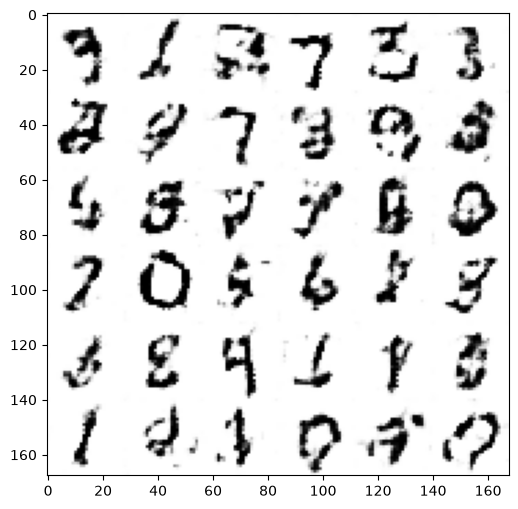

In [10]:
# Testing
# Set the generator to inference mode.
generator.eval()
# Generate images from noise, using the generator network.
n = 6
canvas = np.empty((28 * n, 28 * n))
for i in range(n):
    # Noise input.
    key, noise_key = jax.random.split(key)
    z = jax.random.normal(noise_key, [n, noise_dim])
    # Generate image from noise.
    g = np.asarray(generator(z))
    # Rescale to original [0, 1]
    g = (g + 1.) / 2
    # Reverse colours for better display
    g = -1 * (g - 1)
    for j in range(n):
        # Draw the generated digits
        canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = g[j].reshape([28, 28])

plt.figure(figsize=(n, n))
plt.imshow(canvas, origin="upper", cmap="gray")
plt.show()

With 2000 training steps, the generated images look like handwriting, but
many of them are not real digits yet: train longer (e.g. 20000 steps) to get
clearer digits.